<a href="https://colab.research.google.com/github/mahithkumarp12-ctrl/DA-CA3/blob/main/20241CSE0609(MAHITH_KUMAR_P).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from google.colab import files
import pandas as pd

# Upload dataset
uploaded = files.upload()

# Load CSV file
file_name = "Calendar_2018_geopoint.csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

# Display first 5 rows
display(df.head())

# Display dataset shape
print("\nDataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display information about the dataset
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Saving Calendar_2018_geopoint.csv to Calendar_2018_geopoint (2).csv
Dataset loaded successfully!


,"index,Bulan",Nama_Event,Nama_Sirkuit,Lat,Long
0,"0,14 November 2017",Valencia MotoGP™ Official Test,Circuit Ricardo Tormo SPAIN,39.486863,-0.629870
1,"1,28 January 2018",Sepang MotoGP™ Official Test,Sepang International Circuit MALAYSIA,2.759414,101.731778
2,"2,16 February 2018",Buriram MotoGP™ Official Test,Buriram International Circuit THAILAND,14.957971,103.084925
3,"3,1 March 2018",Qatar MotoGP™ Official Test,Losail International Circuit QATAR,25.486109,51.452779
4,"4,18 March 2018",1 - Grand Prix of Qatar,Losail International Circuit QATAR,25.486109,51.452779



Dataset shape: (23, 5)

Column names:
['index,Bulan', 'Nama_Event', 'Nama_Sirkuit', 'Lat', 'Long']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   index,Bulan   23 non-null     object 
 1   Nama_Event    23 non-null     object 
 2   Nama_Sirkuit  23 non-null     object 
 3   Lat           23 non-null     float64
 4   Long          23 non-null     float64
dtypes: float64(2), object(3)
memory usage: 1.0+ KB

Missing values:
index,Bulan     0
Nama_Event      0
Nama_Sirkuit    0
Lat             0
Long            0
dtype: int64


In [7]:
# Input features
X = df[["Nama_Event", "Nama_Sirkuit"]]

# Target variables
y = df[["Lat", "Long"]]

print("Input features (X):")
display(X.head())

print("\nTarget variables (y):")
display(y.head())

print("\nNumber of input features:", X.shape[1])

print("Number of target values:", y.shape[0])

Input features (X):


,Nama_Event,Nama_Sirkuit
0,Valencia MotoGP™ Official Test,Circuit Ricardo Tormo SPAIN
1,Sepang MotoGP™ Official Test,Sepang International Circuit MALAYSIA
2,Buriram MotoGP™ Official Test,Buriram International Circuit THAILAND
3,Qatar MotoGP™ Official Test,Losail International Circuit QATAR
4,1 - Grand Prix of Qatar,Losail International Circuit QATAR



Target variables (y):


,Lat,Long
0,39.486863,-0.629870
1,2.759414,101.731778
2,14.957971,103.084925
3,25.486109,51.452779
4,25.486109,51.452779



Number of input features: 2
Number of target values: 23


In [8]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nUnique Event Names:")
print(df["Nama_Event"].nunique())

print("\nUnique Circuits:")
print(df["Nama_Sirkuit"].nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   index,Bulan   23 non-null     object 
 1   Nama_Event    23 non-null     object 
 2   Nama_Sirkuit  23 non-null     object 
 3   Lat           23 non-null     float64
 4   Long          23 non-null     float64
dtypes: float64(2), object(3)
memory usage: 1.0+ KB

Missing Values:
index,Bulan     0
Nama_Event      0
Nama_Sirkuit    0
Lat             0
Long            0
dtype: int64

Duplicate Records:
0

Unique Event Names:
23

Unique Circuits:
19


In [9]:
# Separate index and date
df[["Event_Index", "Event_Date"]] = df["index,Bulan"].str.split(
    ",",
    n=1,
    expand=True
)

# Convert index to integer
df["Event_Index"] = df["Event_Index"].astype(int)

# Convert date to datetime
df["Event_Date"] = pd.to_datetime(
    df["Event_Date"],
    format="%d %B %Y"
)

print("Date information separated successfully!")

display(df[["Event_Index", "Event_Date", "Nama_Event"]].head())

Date information separated successfully!


,Event_Index,Event_Date,Nama_Event
0,0,2017-11-14,Valencia MotoGP™ Official Test
1,1,2018-01-28,Sepang MotoGP™ Official Test
2,2,2018-02-16,Buriram MotoGP™ Official Test
3,3,2018-03-01,Qatar MotoGP™ Official Test
4,4,2018-03-18,1 - Grand Prix of Qatar


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))

print("Testing samples:", len(X_test))

print("\nTraining data shape:", X_train.shape)

print("Testing data shape:", X_test.shape)

Training samples: 18
Testing samples: 5

Training data shape: (18, 2)
Testing data shape: (5, 2)


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical data processing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical data processing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Train model
model.fit(X_train, y_train)

print("Random Forest Regression model trained successfully!")

Random Forest Regression model trained successfully!


In [12]:
# Make predictions
y_pred = model.predict(X_test)

# Convert predictions to DataFrame
predictions = pd.DataFrame(
    y_pred,
    columns=["Predicted_Lat", "Predicted_Long"]
)

# Actual values
actual_values = y_test.reset_index(drop=True)

comparison = pd.concat(
    [actual_values, predictions],
    axis=1
)

print("Actual vs Predicted Values:")

display(comparison)

Actual vs Predicted Values:


,Lat,Long,Predicted_Lat,Predicted_Long
0,52.073301,-1.014663,45.226776,16.919398
1,43.997526,11.371879,45.226776,16.919398
2,39.486863,-0.629870,43.458172,12.398463
3,47.953730,0.213367,45.226776,16.919398
4,41.078300,-0.204535,45.226776,16.919398


In [13]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Evaluate latitude
latitude_mae = mean_absolute_error(
    y_test["Lat"],
    y_pred[:, 0]
)

latitude_mse = mean_squared_error(
    y_test["Lat"],
    y_pred[:, 0]
)

latitude_rmse = np.sqrt(latitude_mse)

latitude_r2 = r2_score(
    y_test["Lat"],
    y_pred[:, 0]
)

# Evaluate longitude
longitude_mae = mean_absolute_error(
    y_test["Long"],
    y_pred[:, 1]
)

longitude_mse = mean_squared_error(
    y_test["Long"],
    y_pred[:, 1]
)

longitude_rmse = np.sqrt(longitude_mse)

longitude_r2 = r2_score(
    y_test["Long"],
    y_pred[:, 1]
)

print("MODEL EVALUATION METRICS")

print("\nLatitude:")
print("MAE:", round(latitude_mae, 4))
print("MSE:", round(latitude_mse, 4))
print("RMSE:", round(latitude_rmse, 4))
print("R2 Score:", round(latitude_r2, 4))

print("\nLongitude:")
print("MAE:", round(longitude_mae, 4))
print("MSE:", round(longitude_mse, 4))
print("RMSE:", round(longitude_rmse, 4))
print("R2 Score:", round(longitude_r2, 4))

MODEL EVALUATION METRICS

Latitude:
MAE: 3.7845
MSE: 17.7607
RMSE: 4.2143
R2 Score: 0.1583

Longitude:
MAE: 14.068
MSE: 218.8927
RMSE: 14.795
R2 Score: -8.7829


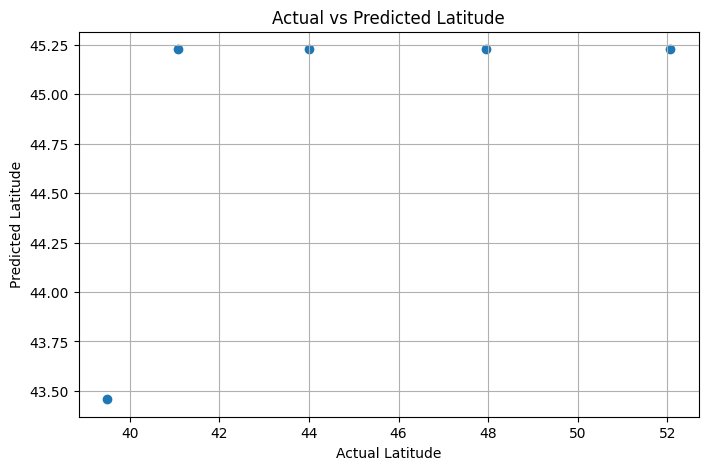

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test["Lat"],
    y_pred[:, 0]
)

plt.xlabel("Actual Latitude")

plt.ylabel("Predicted Latitude")

plt.title("Actual vs Predicted Latitude")

plt.grid(True)

plt.show()

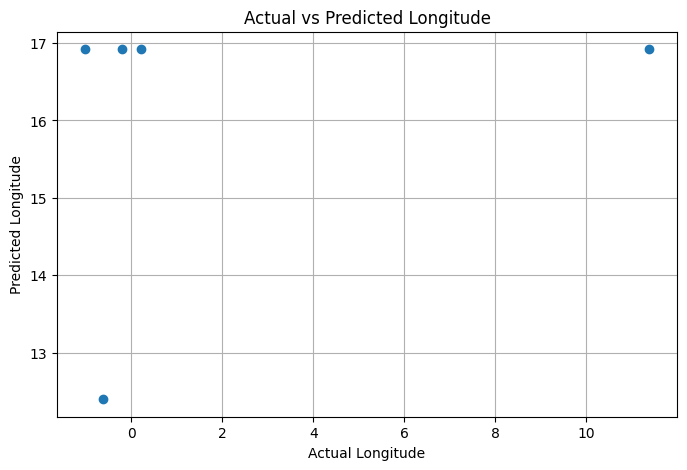

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test["Long"],
    y_pred[:, 1]
)

plt.xlabel("Actual Longitude")

plt.ylabel("Predicted Longitude")

plt.title("Actual vs Predicted Longitude")

plt.grid(True)

plt.show()

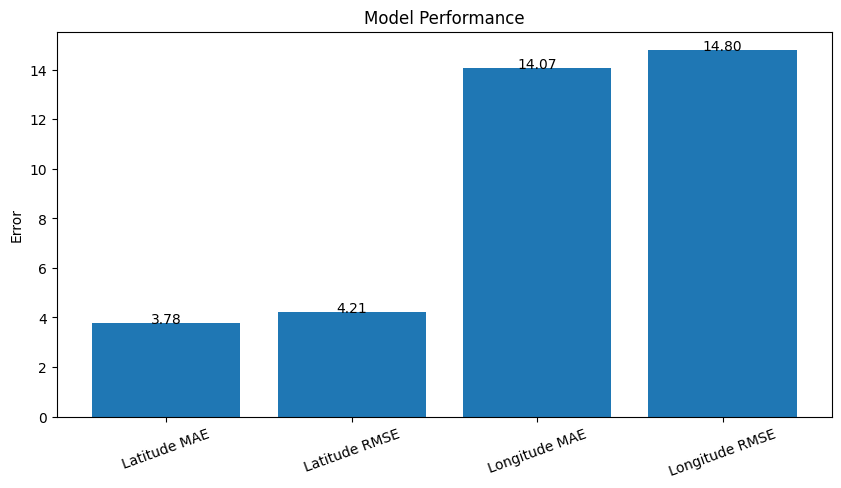

In [16]:
metrics = {
    "Latitude MAE": latitude_mae,
    "Latitude RMSE": latitude_rmse,
    "Longitude MAE": longitude_mae,
    "Longitude RMSE": longitude_rmse
}

plt.figure(figsize=(10, 5))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylabel("Error")

plt.title("Model Performance")

plt.xticks(rotation=20)

for i, value in enumerate(metrics.values()):
    plt.text(
        i,
        value,
        f"{value:.2f}",
        ha="center"
    )

plt.show()

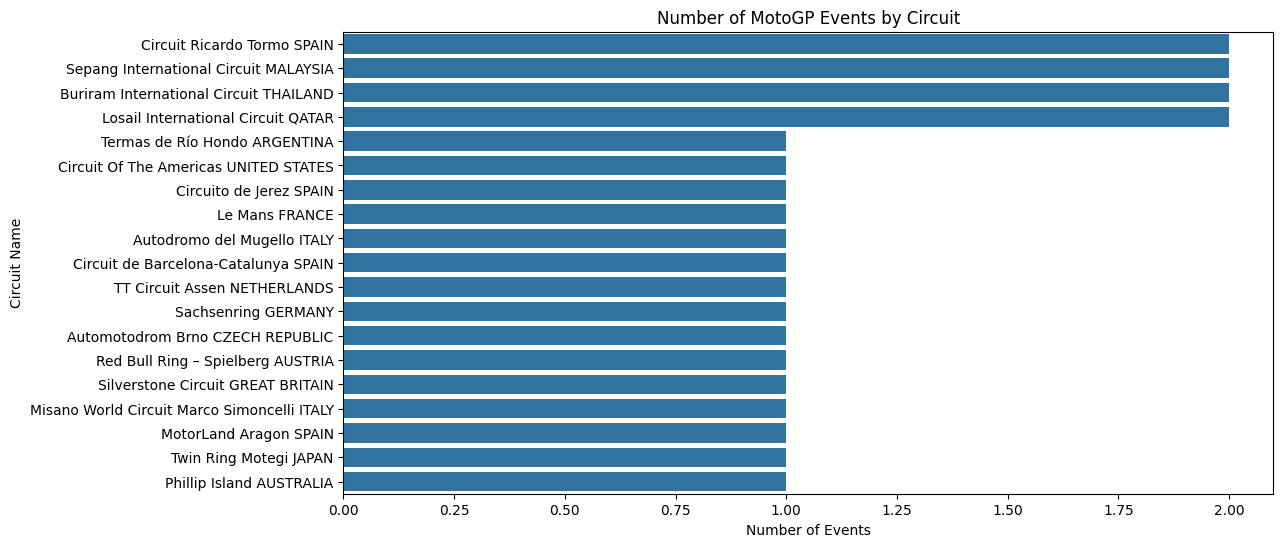

In [17]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Nama_Sirkuit",
    order=df["Nama_Sirkuit"].value_counts().index
)

plt.title("Number of MotoGP Events by Circuit")

plt.xlabel("Number of Events")

plt.ylabel("Circuit Name")

plt.show()

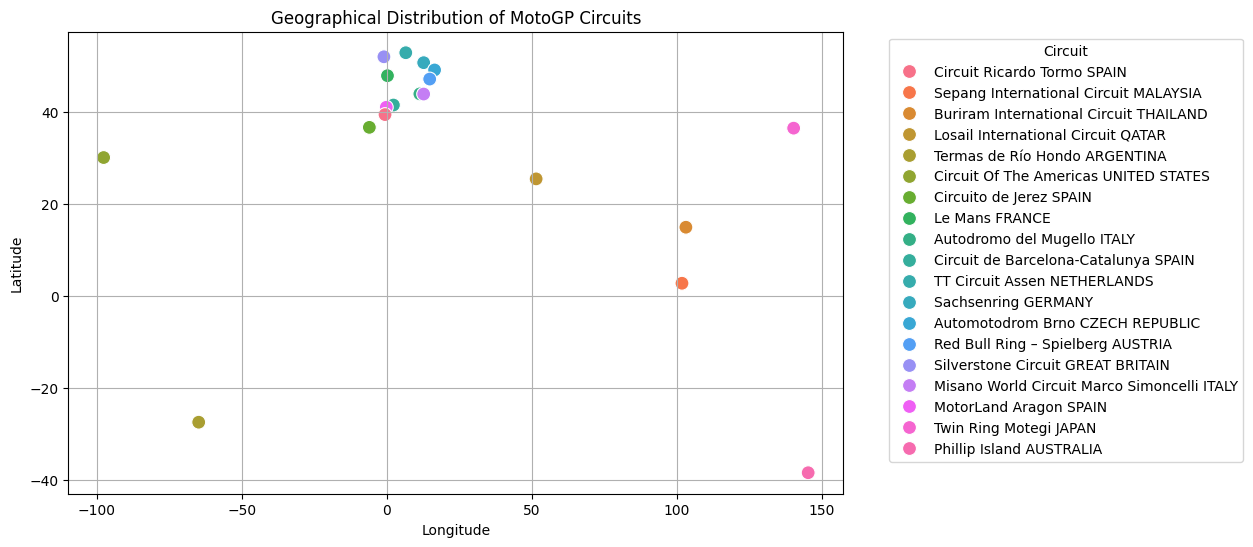

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Long",
    y="Lat",
    hue="Nama_Sirkuit",
    s=100
)

plt.title("Geographical Distribution of MotoGP Circuits")

plt.xlabel("Longitude")

plt.ylabel("Latitude")

plt.grid(True)

plt.legend(
    title="Circuit",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

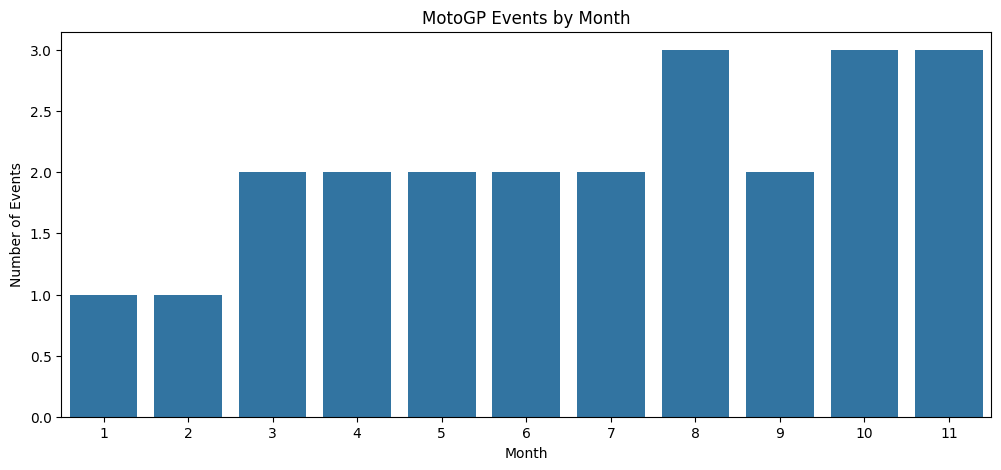

In [19]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x=df["Event_Date"].dt.month
)

plt.title("MotoGP Events by Month")

plt.xlabel("Month")

plt.ylabel("Number of Events")

plt.show()

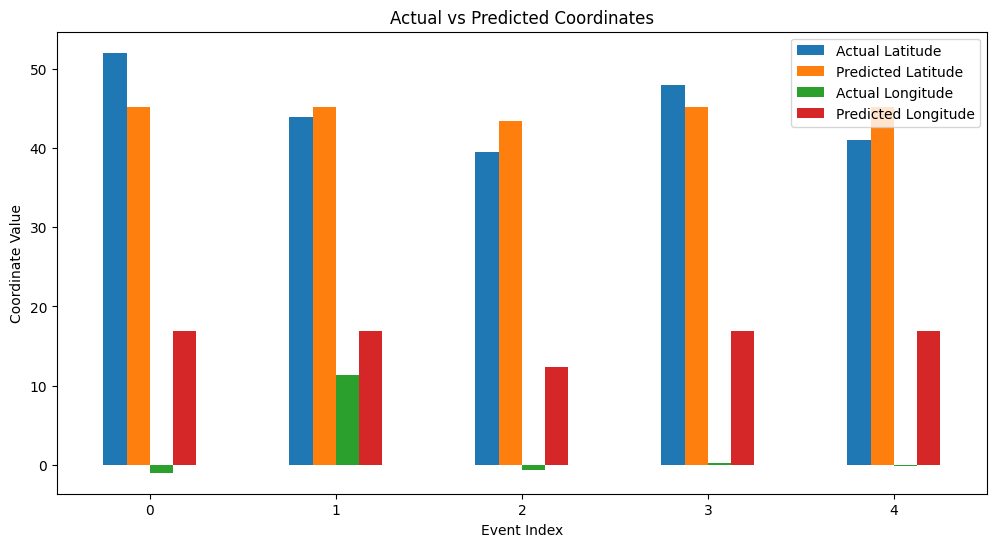

In [20]:
comparison = pd.DataFrame({
    "Actual Latitude": y_test["Lat"].values,
    "Predicted Latitude": y_pred[:, 0],
    "Actual Longitude": y_test["Long"].values,
    "Predicted Longitude": y_pred[:, 1]
})

comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Actual vs Predicted Coordinates")

plt.xlabel("Event Index")

plt.ylabel("Coordinate Value")

plt.xticks(rotation=0)

plt.legend()

plt.show()

In [21]:
import os
import zipfile
from google.colab import files

# Create visualization folder
os.makedirs("visualizations", exist_ok=True)

# 1. Actual vs Predicted Latitude
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test["Lat"],
    y_pred[:, 0]
)

plt.xlabel("Actual Latitude")
plt.ylabel("Predicted Latitude")

plt.title("Actual vs Predicted Latitude")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "visualizations/latitude_prediction.png",
    dpi=300
)

plt.close()


# 2. Actual vs Predicted Longitude
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test["Long"],
    y_pred[:, 1]
)

plt.xlabel("Actual Longitude")
plt.ylabel("Predicted Longitude")

plt.title("Actual vs Predicted Longitude")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "visualizations/longitude_prediction.png",
    dpi=300
)

plt.close()


# 3. Model Performance
plt.figure(figsize=(10, 5))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylabel("Error")

plt.title("Model Performance")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "visualizations/model_performance.png",
    dpi=300
)

plt.close()


# 4. Events by Circuit
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Nama_Sirkuit",
    order=df["Nama_Sirkuit"].value_counts().index
)

plt.title("Number of Events by Circuit")

plt.tight_layout()

plt.savefig(
    "visualizations/events_by_circuit.png",
    dpi=300
)

plt.close()


# 5. Geographical Distribution
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Long",
    y="Lat",
    hue="Nama_Sirkuit",
    s=100
)

plt.title("Geographical Distribution of MotoGP Circuits")

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()

plt.savefig(
    "visualizations/geographical_distribution.png",
    dpi=300
)

plt.close()


# 6. Events by Month
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x=df["Event_Date"].dt.month
)

plt.title("MotoGP Events by Month")

plt.xlabel("Month")

plt.ylabel("Number of Events")

plt.tight_layout()

plt.savefig(
    "visualizations/events_by_month.png",
    dpi=300
)

plt.close()


# Create ZIP file
zip_filename = "motogp_visualizations.zip"

with zipfile.ZipFile(zip_filename, "w") as zip_file:

    for filename in os.listdir("visualizations"):

        zip_file.write(
            os.path.join("visualizations", filename),
            arcname=filename
        )

print("All visualizations saved successfully!")

# Download ZIP file
files.download(zip_filename)

All visualizations saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>